In [ ]:
# Cats vs Dogs

'''
x1 weight in kg
x2 nose length

z = b + w1x1 + w2x2 > (what are the odds that it is an dog) P(dog) = sigmoid(z)
'''

In [13]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

In [ ]:
# 1. Data
# Synthetic Data: 

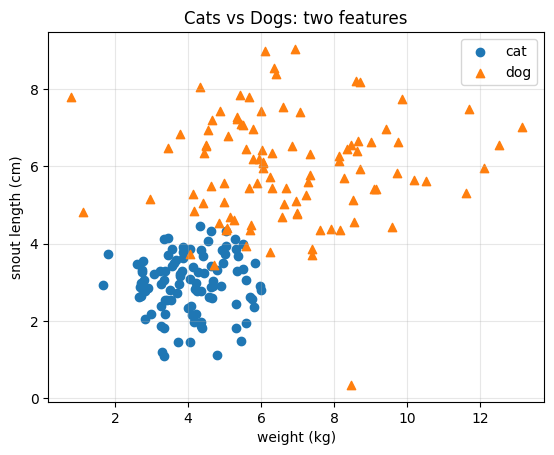

In [14]:
rng = np.random.default_rng(0) # rng = Random Number Generator
n = 100
cats = np.column_stack([rng.normal(4, 1, n), rng.normal(3, 0.8, n)])   # [वजन kg, नाकाची लांबी cm]
dogs = np.column_stack([rng.normal(7, 2, n), rng.normal(6, 1.5, n)])
X = np.vstack([cats, dogs])
y = np.r_[np.zeros(n), np.ones(n)]            # 0 = cat, 1 = dog

plt.scatter(cats[:, 0], cats[:, 1], marker="o", label="cat")
plt.scatter(dogs[:, 0], dogs[:, 1], marker="^", label="dog")
plt.xlabel("weight (kg)")
plt.ylabel("snout length (cm)")
plt.title("Cats vs Dogs: two features")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [18]:
# 2. Training: NLL(Negative Log Likelihood
# gradient dL/dW = (p - y).x > ??

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(2)
b = 0.0
lr = 0.1

for step in range(3001):
    p = sigmoid(X @ w + b) # Activation (x*1w1 + x2*w2 + b)
    nll = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) # why, a mean - I need an analogy for it!

    # Update weights with derivative that we calculated before
    w -= lr * X.T @ (p - y) / len(y)
    b -= lr * np.mean(p - y)
    if step % 1000 == 0:
        print(f"step {step}: NLL = {nll:.3f}")

print("w =", w.round(2), " b =", round(b, 2))
print("accuracy =", np.mean((p > 0.5) == y))

print("e^w =", np.exp(w).round(2), " (प्रत्येक 1 kg / 1 cm ने कुत्र्याचे odds किती पट होतात)")

step 0: NLL = 0.693
step 1000: NLL = 0.237
step 2000: NLL = 0.191
step 3000: NLL = 0.173
w = [0.56 1.49]  b = -9.04
accuracy = 0.96
e^w = [1.75 4.43]  (प्रत्येक 1 kg / 1 cm ने कुत्र्याचे odds किती पट होतात)


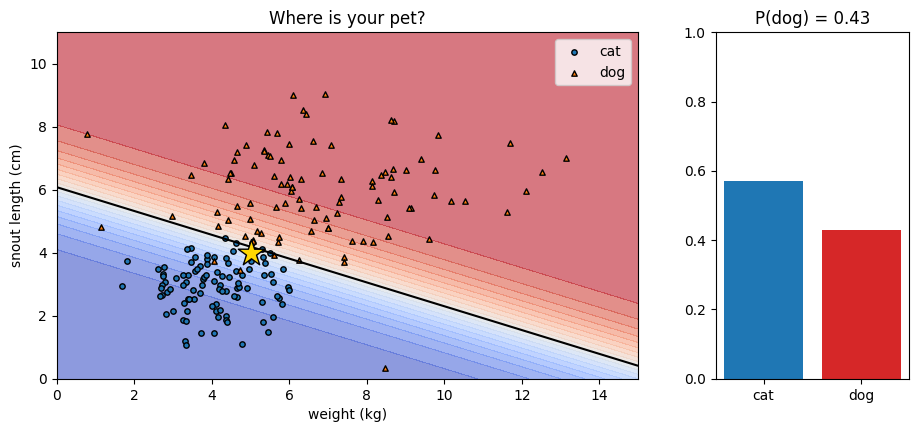

गुण (log odds):  b = -9.04,  वजन = +2.81,  नाक = +5.95
z = -0.28   odds = e^z = 0.754   P(dog) = σ(z) = 0.43


interactive(children=(FloatSlider(value=5.0, description='weight kg', max=40.0, min=0.5, step=0.5), FloatSlide…

In [19]:
# 3 - adding sliders for the same
def plot_pet(weight, snout, ax_map, ax_bar, title=None):
    xmax = max(15, weight * 1.15)
    ymax = max(11, snout * 1.15)
    g1, g2 = np.meshgrid(np.linspace(0, xmax, 200), np.linspace(0, ymax, 200))
    P = sigmoid(w[0] * g1 + w[1] * g2 + b)
    ax_map.contourf(g1, g2, P, levels=20, cmap="coolwarm", alpha=0.6, vmin=0, vmax=1)
    ax_map.contour(g1, g2, P, levels=[0.5], colors="black")
    ax_map.scatter(cats[:, 0], cats[:, 1], marker="o", s=15, edgecolor="k", label="cat")
    ax_map.scatter(dogs[:, 0], dogs[:, 1], marker="^", s=15, edgecolor="k", label="dog")
    ax_map.scatter([weight], [snout], marker="*", s=400, color="gold", edgecolor="k", zorder=5)
    ax_map.set_xlabel("weight (kg)")
    ax_map.set_ylabel("snout length (cm)")
    ax_map.set_title(title or "Where is your pet?")
    ax_map.legend(loc="upper right")

    p_dog = sigmoid(b + w[0] * weight + w[1] * snout)
    ax_bar.bar(["cat", "dog"], [1 - p_dog, p_dog], color=["tab:blue", "tab:red"])
    ax_bar.set_ylim(0, 1)
    ax_bar.set_title(f"P(dog) = {p_dog:.2f}")
    return p_dog


@interact(weight=widgets.FloatSlider(value=5, min=0.5, max=40, step=0.5, description="weight kg"),
          snout=widgets.FloatSlider(value=4, min=0.5, max=14, step=0.5, description="snout cm"))
def build_your_pet(weight, snout):
    fig, (ax_map, ax_bar) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [3, 1]})
    p_dog = plot_pet(weight, snout, ax_map, ax_bar)
    plt.show()
    z = b + w[0] * weight + w[1] * snout
    print(f"गुण (log odds):  b = {b:+.2f},  वजन = {w[0] * weight:+.2f},  नाक = {w[1] * snout:+.2f}")
    print(f"z = {z:+.2f}   odds = e^z = {np.exp(z):.3g}   P(dog) = σ(z) = {p_dog:.2f}")

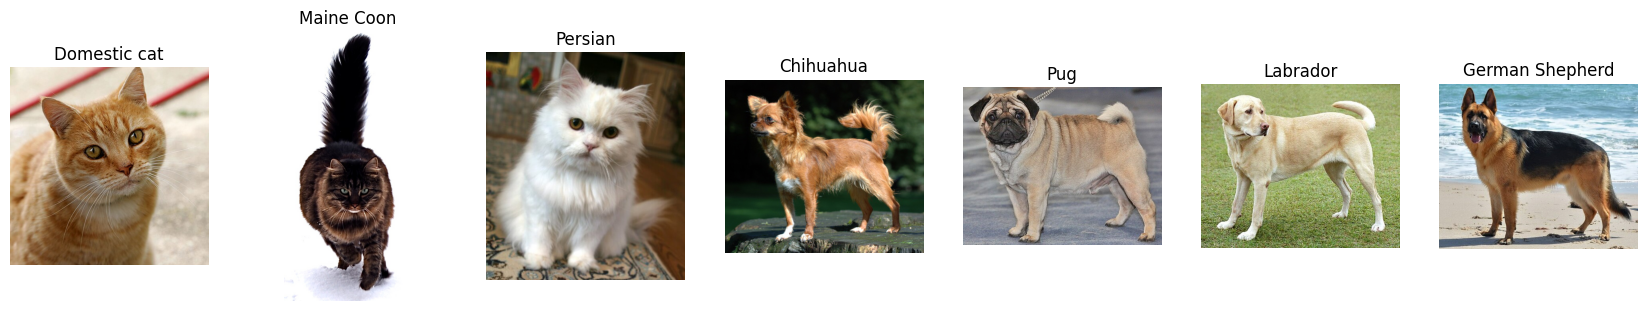

Photos: Wikimedia Commons
  https://commons.wikimedia.org/wiki/File:Cat03.jpg
  https://commons.wikimedia.org/wiki/File:Maine_Coon_cat_by_Tomitheos.JPG
  https://commons.wikimedia.org/wiki/File:White_Persian_Cat.jpg
  https://commons.wikimedia.org/wiki/File:Chihuahua1_bvdb.jpg
  https://commons.wikimedia.org/wiki/File:Mops_oct09_cropped2.jpg
  https://commons.wikimedia.org/wiki/File:YellowLabradorLooking_new.jpg
  https://commons.wikimedia.org/wiki/File:German_Shepherd_-_DSC_0346_(10096362833).jpg


In [21]:
# 4 wikimedia commons

import io
import os
import requests
from PIL import Image

# वजन आणि नाकाची लांबी: अंदाजे आकडे. वर्गात चर्चा करून बदला!
pets = [
    {"name": "Domestic cat", "label": "cat", "weight": 4.5, "snout": 3.0, "file": "Cat03.jpg"},
    {"name": "Maine Coon",   "label": "cat", "weight": 7.0, "snout": 3.5, "file": "Maine_Coon_cat_by_Tomitheos.JPG"},
    {"name": "Persian",      "label": "cat", "weight": 4.0, "snout": 1.0, "file": "White_Persian_Cat.jpg"},
    {"name": "Chihuahua",    "label": "dog", "weight": 2.0, "snout": 3.0, "file": "Chihuahua1_bvdb.jpg"},
    {"name": "Pug",          "label": "dog", "weight": 7.0, "snout": 1.5, "file": "Mops_oct09_cropped2.jpg"},
    {"name": "Labrador",     "label": "dog", "weight": 30.0, "snout": 10.0, "file": "YellowLabradorLooking_new.jpg"},
    {"name": "German Shepherd", "label": "dog", "weight": 35.0, "snout": 12.0,
     "file": "German_Shepherd_-_DSC_0346_(10096362833).jpg"},
]

HEADERS = {"User-Agent": "CourseOfAI-classroom-notebook/1.0 (teaching demo)"}
os.makedirs("pet_photos", exist_ok=True)

def load_photo(pet):
    path = os.path.join("pet_photos", pet["file"].replace("/", "_"))
    if not os.path.exists(path):
        url = "https://commons.wikimedia.org/wiki/Special:FilePath/" + pet["file"] + "?width=400"
        try:
            r = requests.get(url, headers=HEADERS, timeout=20)
            r.raise_for_status()
            with open(path, "wb") as f:
                f.write(r.content)
        except Exception as e:
            print(f"{pet['name']}: photo download झाला नाही ({e})")
            return None
    return Image.open(path).convert("RGB")

for pet in pets:
    pet["photo"] = load_photo(pet)

fig, axes = plt.subplots(1, len(pets), figsize=(3 * len(pets), 3.5))
for ax, pet in zip(axes, pets):
    if pet["photo"] is not None:
        ax.imshow(pet["photo"])
    ax.set_title(pet["name"])
    ax.axis("off")
plt.show()

print("Photos: Wikimedia Commons")
for pet in pets:
    print("  https://commons.wikimedia.org/wiki/File:" + pet["file"])

In [22]:
print(f"{'pet':16s} {'kg':>5s} {'cm':>5s}   P(dog)   model   खरं")
for pet in pets:
    p_dog = sigmoid(b + w[0] * pet["weight"] + w[1] * pet["snout"])
    guess = "dog" if p_dog > 0.5 else "cat"
    mark = "✅" if guess == pet["label"] else "❌"
    print(f"{pet['name']:16s} {pet['weight']:5.1f} {pet['snout']:5.1f}   {p_dog:6.2f}   {guess:5s}   {pet['label']:4s} {mark}")

pet                 kg    cm   P(dog)   model   खरं
Domestic cat       4.5   3.0     0.11   cat     cat  ✅
Maine Coon         7.0   3.5     0.52   dog     cat  ❌
Persian            4.0   1.0     0.00   cat     cat  ✅
Chihuahua          2.0   3.0     0.03   cat     dog  ❌
Pug                7.0   1.5     0.05   cat     dog  ❌
Labrador          30.0  10.0     1.00   dog     dog  ✅
German Shepherd   35.0  12.0     1.00   dog     dog  ✅
